In [6]:
import numpy as np
import matplotlib.pyplot as plt

from musim.core.stimuli import *
from musim.neuron_models.lif import LIFModel

In [ ]:
"""
Set up the LIF model with 100 neurons
and soma diametrs from 50 to 100 micro meters

"""

n_mn = 100

model = LIFModel(
    n_mn=n_mn,
    dist_exp=3,
    d_soma=(50e-6, 70e-6)
)

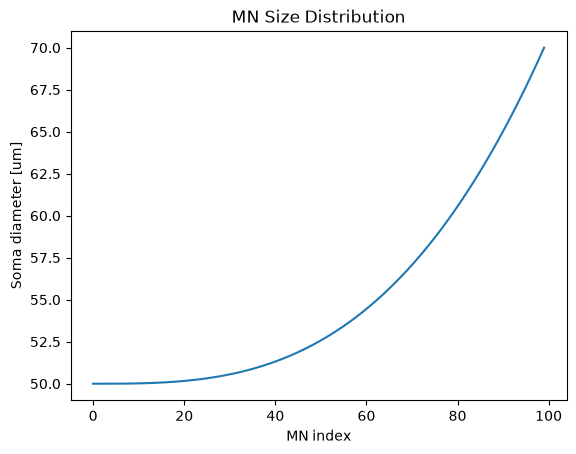

In [8]:
"""
Show the distribution 
of soma diameters

"""

plt.figure()
plt.plot(model.param["soma_diam"] * 1e6)
plt.xlabel("MN index")
plt.ylabel("Soma diameter [um]")
plt.title("MN Size Distribution")
plt.show()

In [9]:
"""
Make a trapezoid drive with 
    - 3 seconds ramp up
    - 10 seconds steady effort
    - 3 seconds ramp down

The mean drive at the plateau is 10 nano Ampere

In the given pool, MNs are recruited roughly between
7.5 nA and 17 nA
    
"""

dt = 0.1

CI = trapezoid_drive(
    t_plateau=10000, # milli seconds
    t_ramp=3000,     # milli seconds
    dt=dt,          # milli seconds
    max_CI=10,       # nano ampere
    min_CI=7,        # nano ampere   
    n_mu=100,
)

In [10]:
"""
Do a simulation with the given drive

"""

v, spikes = model.simulate(CI, dt=dt)

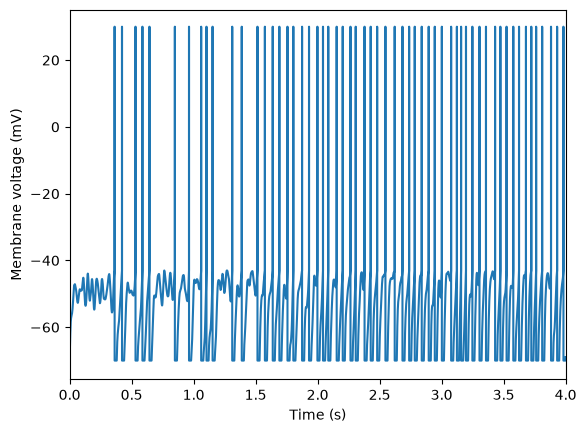

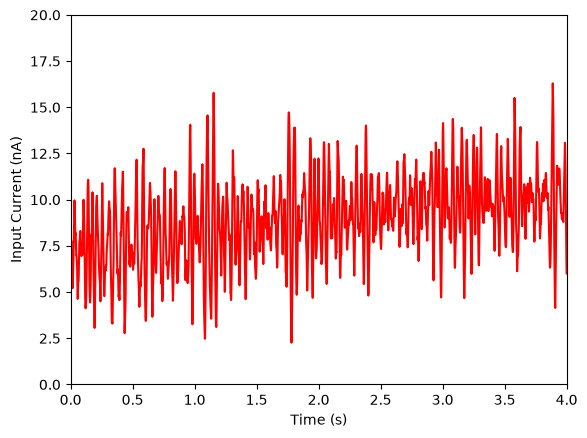

In [17]:
t = np.arange(v.shape[1]) * dt / 1000

plt.figure()
plt.plot(t,v[0, :])
plt.xlim(0, 4)
plt.xlabel("Time (s)")
plt.ylabel("Membrane voltage (mV)")
plt.show()

plt.figure()
plt.plot(t,CI[0, :], color="red")
plt.xlim(0, 4)
plt.ylim(0, 20)
plt.xlabel("Time (s)")
plt.ylabel("Input Current (nA)")
plt.show()

In [ ]:


active_mask = np.zeros(n_mn, dtype=bool)
cov = np.zeros(n_mn)

n_active = 0
for i in range(n_mn):
    
    if len(spikes[i]) > 50:

        active_mask[i] = True
        n_active += 1

        mu_spikes = spikes[i]
        mu_spikes = mu_spikes[mu_spikes > 3]
        mu_spikes = mu_spikes[mu_spikes < 13]

        isi = np.diff(mu_spikes)
        cov[i] = np.std(isi) / np.mean(isi) * 100

print(f"The number of active MNs is {n_active}")

plt.figure()
plt.plot(cov)
plt.xlabel("MN Index")
plt.ylabel("CoV-ISI (%)")
plt.title("Spike Variability")
plt.show()